In [1]:
import sys
from pathlib import Path

project_root = Path("/mnt/x/segmentation_cfos")
sys.path.insert(0, str(project_root))

import numpy as np
import matplotlib.pyplot as plt
import random
from src.data.io_utils import read_tif_image, convert_image_to_array

In [2]:
images_patches = Path("/mnt/x/donnees/pachs_64_3classes_filtered_slices/images")
masks_patches = Path("/mnt/x/donnees/pachs_64_3classes_filtered_slices/masks")

print(f"Images existent: {images_patches.exists()}")
print(f"Masks existent: {masks_patches.exists()}")

Images existent: True
Masks existent: True


In [3]:
image_files = sorted(images_patches.glob("*.tif"))
mask_files = sorted(masks_patches.glob("*.tif"))

print(f"Total patches après filtrage: {len(image_files)}")
print(f"Total masks: {len(mask_files)}")

# Sélectionner 2500 patches aléatoires
SAMPLE_SIZE = 2500
random.seed(42)
selected_indices = random.sample(range(len(image_files)), min(SAMPLE_SIZE, len(image_files)))

print(f"Patches sélectionnés: {len(selected_indices)}")


Total patches après filtrage: 6182
Total masks: 6182
Patches sélectionnés: 2500


In [4]:
print("Analyse des classes...")
print("-" * 40)

total_voxels = 0
total_c0 = 0
total_c1 = 0
total_c2 = 0

for i, idx in enumerate(selected_indices):
    mask_file = mask_files[idx]
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    
    total_voxels += mask.size
    total_c0 += (mask == 0).sum()
    total_c1 += (mask == 1).sum()
    total_c2 += (mask == 2).sum()
    
    if (i + 1) % 500 == 0:
        print(f"  Analysé {i+1}/{len(selected_indices)} patches")

print(f"\n✅ Analyse terminée!")


Analyse des classes...
----------------------------------------
  Analysé 500/2500 patches
  Analysé 1000/2500 patches
  Analysé 1500/2500 patches
  Analysé 2000/2500 patches
  Analysé 2500/2500 patches

✅ Analyse terminée!


In [5]:
pct0 = (total_c0 / total_voxels) * 100
pct1 = (total_c1 / total_voxels) * 100
pct2 = (total_c2 / total_voxels) * 100

print("=" * 50)
print("RÉSULTATS - DISTRIBUTION DES CLASSES (Seuil 40)")
print("=" * 50)
print(f"Patches analysés: {len(selected_indices):,}")
print(f"Total voxels: {total_voxels:,}")
print()
print(f"Classe 0 (Fond):        {pct0:.2f}%  ({total_c0:,} voxels)")
print(f"Classe 1 (Neurones):    {pct1:.4f}%  ({total_c1:,} voxels)")
print(f"Classe 2 (Vaisseaux):   {pct2:.4f}%  ({total_c2:,} voxels)")
print()
print(f"Ratio Fond/Neurones:     {total_c0/total_c1:.1f}")
print(f"Ratio Fond/Vaisseaux:    {total_c0/total_c2:.1f}")

RÉSULTATS - DISTRIBUTION DES CLASSES (Seuil 40)
Patches analysés: 2,500
Total voxels: 655,360,000

Classe 0 (Fond):        97.85%  (641,279,554 voxels)
Classe 1 (Neurones):    0.3051%  (1,999,747 voxels)
Classe 2 (Vaisseaux):   1.8434%  (12,080,699 voxels)

Ratio Fond/Neurones:     320.7
Ratio Fond/Vaisseaux:    53.1


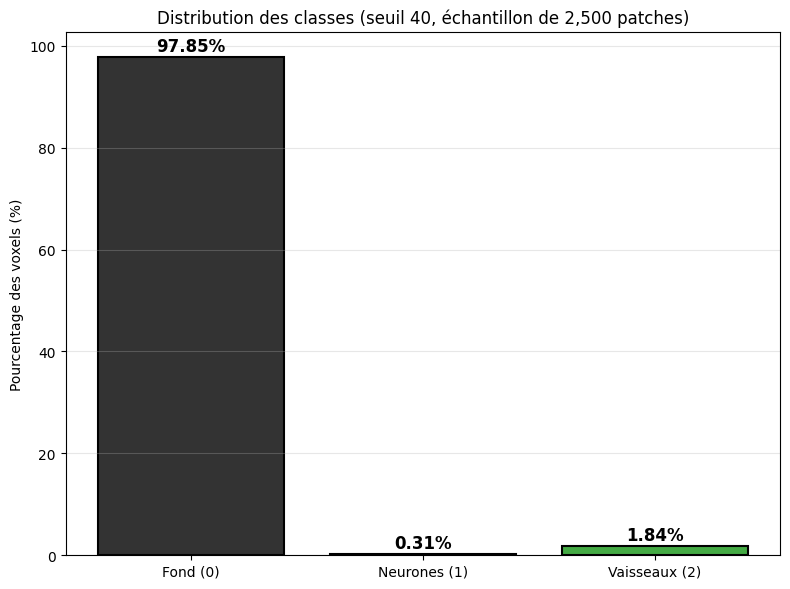

In [6]:
fig, ax = plt.subplots(figsize=(8, 6))

classes = ['Fond (0)', 'Neurones (1)', 'Vaisseaux (2)']
percentages = [pct0, pct1, pct2]
colors = ['#333333', '#FF4444', '#44AA44']

bars = ax.bar(classes, percentages, color=colors, edgecolor='black', linewidth=1.5)

for bar, pct in zip(bars, percentages):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{pct:.2f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.set_ylabel('Pourcentage des voxels (%)')
ax.set_title(f'Distribution des classes (seuil 40, échantillon de {len(selected_indices):,} patches)')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.show()

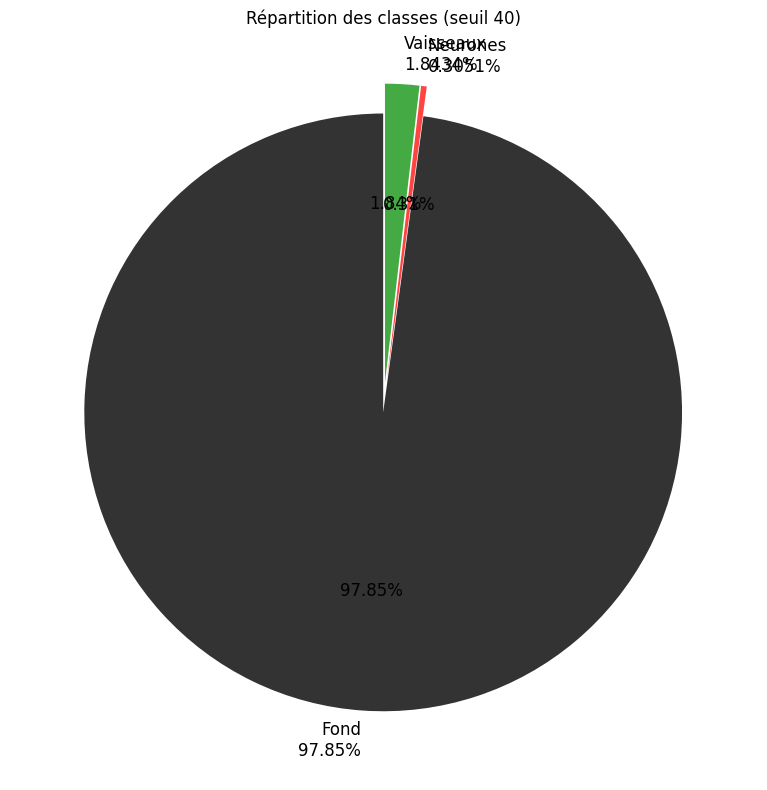

In [7]:
fig, ax = plt.subplots(figsize=(8, 8))

labels = [f'Fond\n{pct0:.2f}%', f'Neurones\n{pct1:.4f}%', f'Vaisseaux\n{pct2:.4f}%']
colors = ['#333333', '#FF4444', '#44AA44']
explode = (0.02, 0.08, 0.08)

wedges, texts, autotexts = ax.pie(
    percentages, 
    labels=labels, 
    colors=colors, 
    explode=explode,
    autopct='%1.2f%%',
    startangle=90,
    textprops={'fontsize': 12}
)

ax.set_title(f'Répartition des classes (seuil 40)')
plt.tight_layout()
plt.show()

In [8]:
def show_patch(image_path, mask_path, slice_idx=None):
    image_sitk = read_tif_image(str(image_path))
    mask_sitk = read_tif_image(str(mask_path))
    
    image = convert_image_to_array(image_sitk)
    mask = convert_image_to_array(mask_sitk)
    
    if slice_idx is None:
        slice_idx = image.shape[0] // 2
    
    img_slice = image[slice_idx, :, :]
    if img_slice.max() > 1:
        img_slice = img_slice / img_slice.max()
    
    mask_slice = mask[slice_idx, :, :]
    
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    rgb_mask[mask_slice == 2] = [0, 1, 0]
    
    overlay = np.stack([img_slice, img_slice, img_slice], axis=-1)
    overlay[mask_slice == 1, 0] = 1
    overlay[mask_slice == 1, 1] = 0
    overlay[mask_slice == 1, 2] = 0
    overlay[mask_slice == 2, 0] = 0
    overlay[mask_slice == 2, 1] = 1
    overlay[mask_slice == 2, 2] = 0
    
    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title(f'Image - Slice {slice_idx}')
    axes[0].axis('off')
    
    axes[1].imshow(rgb_mask)
    axes[1].set_title('Mask 3 Classes')
    axes[1].axis('off')
    
    axes[2].imshow(overlay)
    axes[2].set_title('Superposition')
    axes[2].axis('off')
    
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='black', label='Fond (0)'),
        Patch(facecolor='red', label='Neurones (1)'),
        Patch(facecolor='green', label='Vaisseaux (2)')
    ]
    axes[2].legend(handles=legend_elements, loc='upper right', bbox_to_anchor=(1.15, 1))
    
    plt.suptitle(f'{image_path.name}')
    plt.tight_layout()
    plt.show()
    
    print(f"  Classe 0: {(mask == 0).sum():,}")
    print(f"  Classe 1: {(mask == 1).sum():,}")
    print(f"  Classe 2: {(mask == 2).sum():,}")



VISUALISATION D'UN PATCH ALÉATOIRE
Patch: sample_033000292.tif


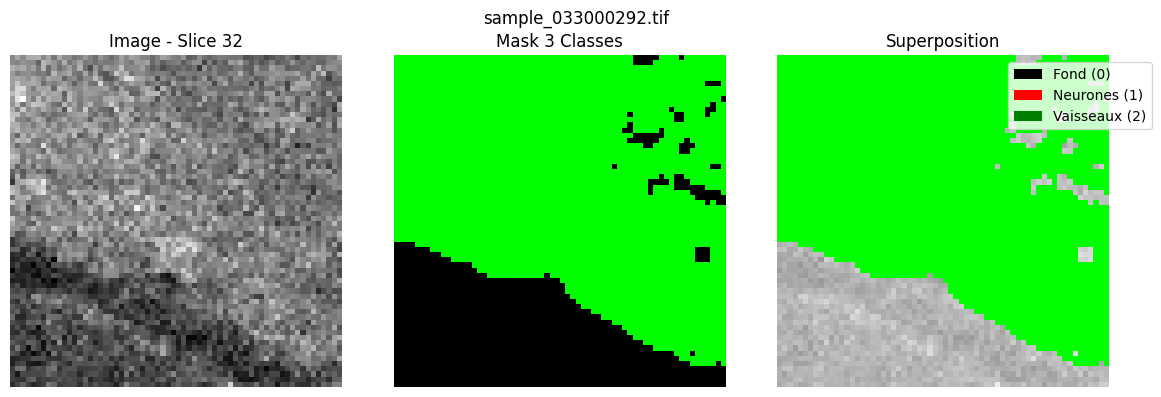

  Classe 0: 103,005
  Classe 1: 690
  Classe 2: 158,449


In [14]:
print("\n" + "=" * 50)
print("VISUALISATION D'UN PATCH ALÉATOIRE")
print("=" * 50)

random_idx = random.choice(selected_indices)
print(f"Patch: {image_files[random_idx].name}")
show_patch(image_files[random_idx], mask_files[random_idx])



VISUALISATION DE 10 PATCHES ALÉATOIRES (GRILLE)


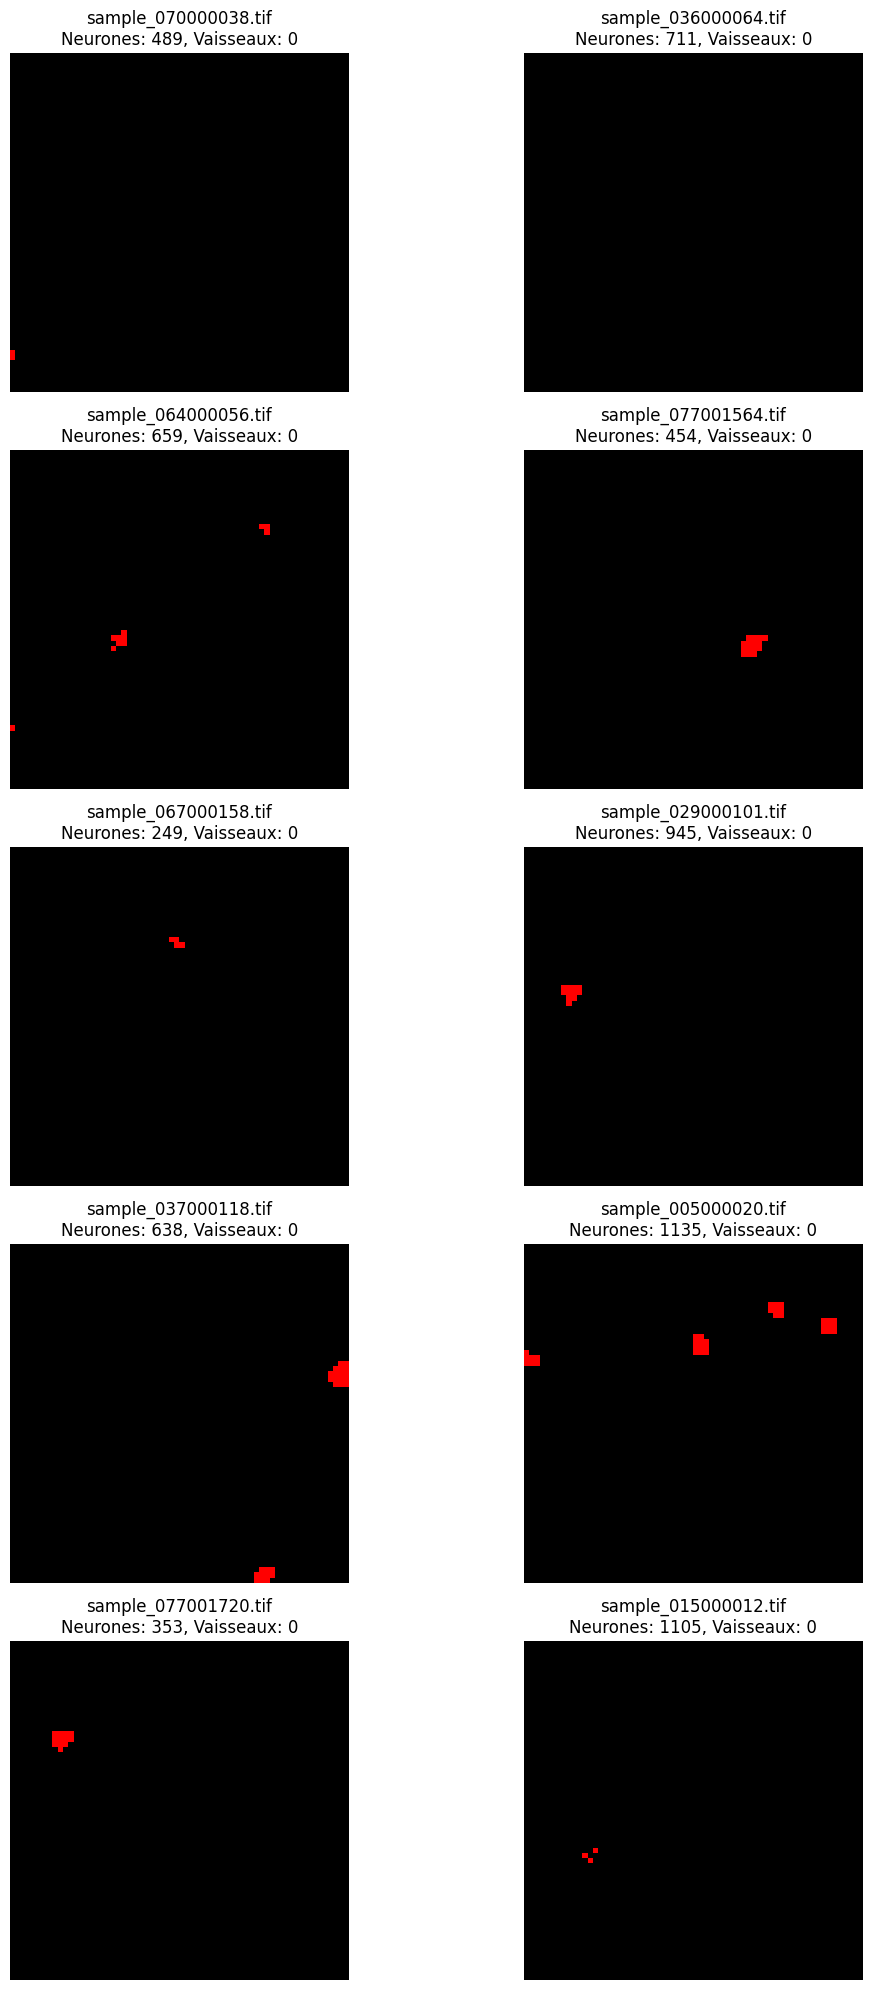

In [16]:

print("\n" + "=" * 50)
print("VISUALISATION DE 10 PATCHES ALÉATOIRES (GRILLE)")
print("=" * 50)

random_indices = random.sample(selected_indices, min(10, len(selected_indices)))

# Créer une grille 5x2
fig, axes = plt.subplots(5, 2, figsize=(12, 20))
axes = axes.flatten()

for i, idx in enumerate(random_indices):
    mask_file = mask_files[idx]
    mask_sitk = read_tif_image(str(mask_file))
    mask = convert_image_to_array(mask_sitk)
    
    slice_idx = mask.shape[0] // 2
    mask_slice = mask[slice_idx, :, :]
    
    rgb_mask = np.zeros((mask_slice.shape[0], mask_slice.shape[1], 3), dtype=np.float32)
    rgb_mask[mask_slice == 0] = [0, 0, 0]
    rgb_mask[mask_slice == 1] = [1, 0, 0]
    rgb_mask[mask_slice == 2] = [0, 1, 0]
    
    axes[i].imshow(rgb_mask)
    axes[i].set_title(f"{image_files[idx].name}\nNeurones: {(mask==1).sum()}, Vaisseaux: {(mask==2).sum()}")
    axes[i].axis('off')

# Cacher les axes vides
for j in range(len(random_indices), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()


VISUALISATION DE 10 PATCHES ALÉATOIRES

--- Patch 1/10: sample_077001250.tif ---


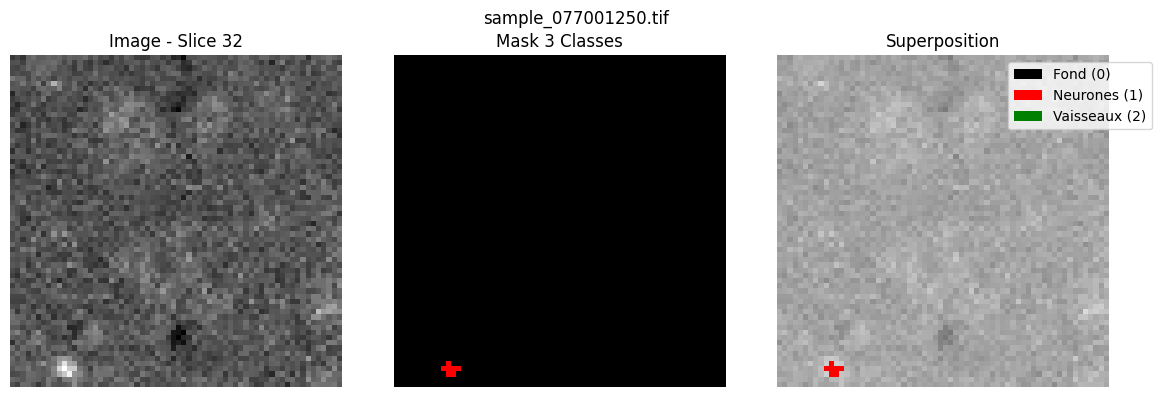

  Classe 0: 261,827
  Classe 1: 317
  Classe 2: 0

--- Patch 2/10: sample_070000084.tif ---


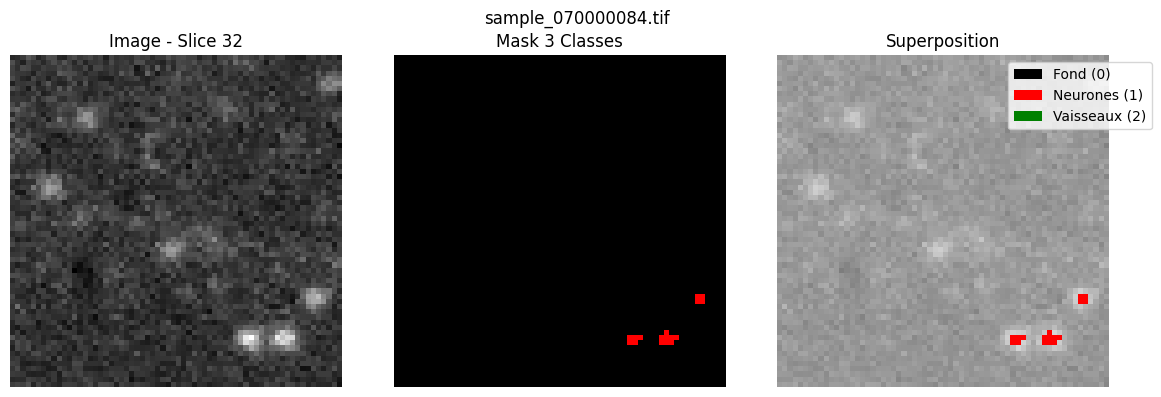

  Classe 0: 260,940
  Classe 1: 1,204
  Classe 2: 0

--- Patch 3/10: sample_043000149.tif ---


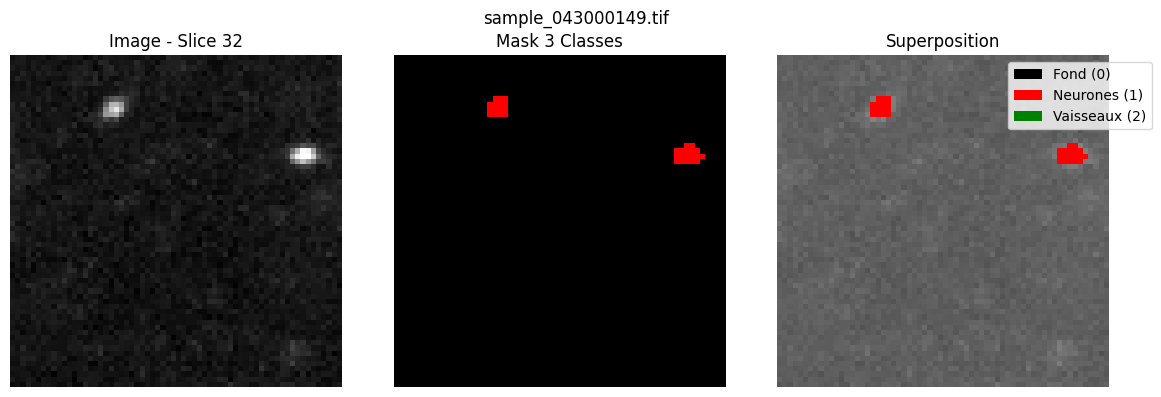

  Classe 0: 260,094
  Classe 1: 2,050
  Classe 2: 0

--- Patch 4/10: sample_033000198.tif ---


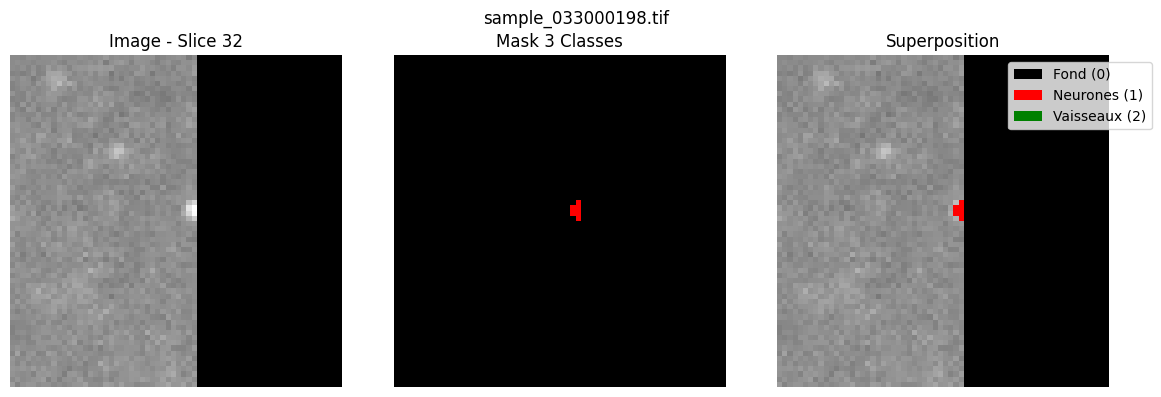

  Classe 0: 261,285
  Classe 1: 706
  Classe 2: 153

--- Patch 5/10: sample_071000193.tif ---


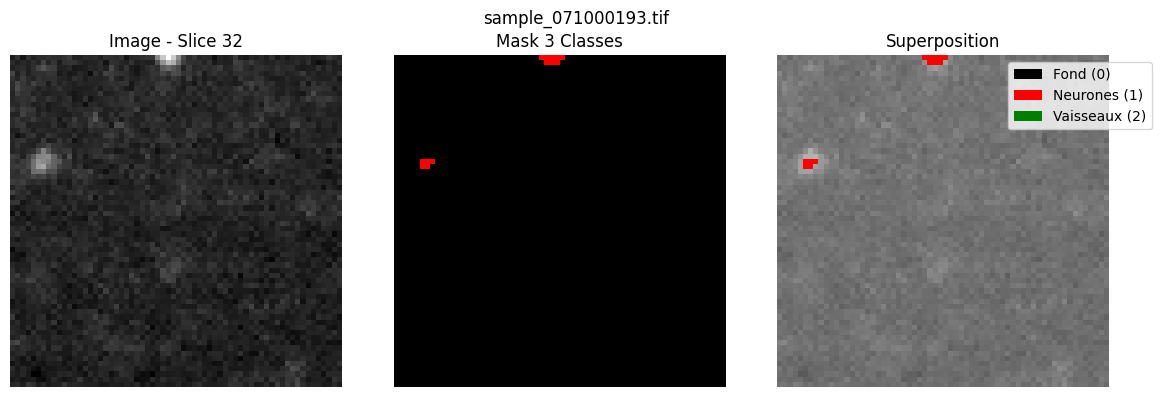

  Classe 0: 261,600
  Classe 1: 544
  Classe 2: 0

--- Patch 6/10: sample_032000190.tif ---


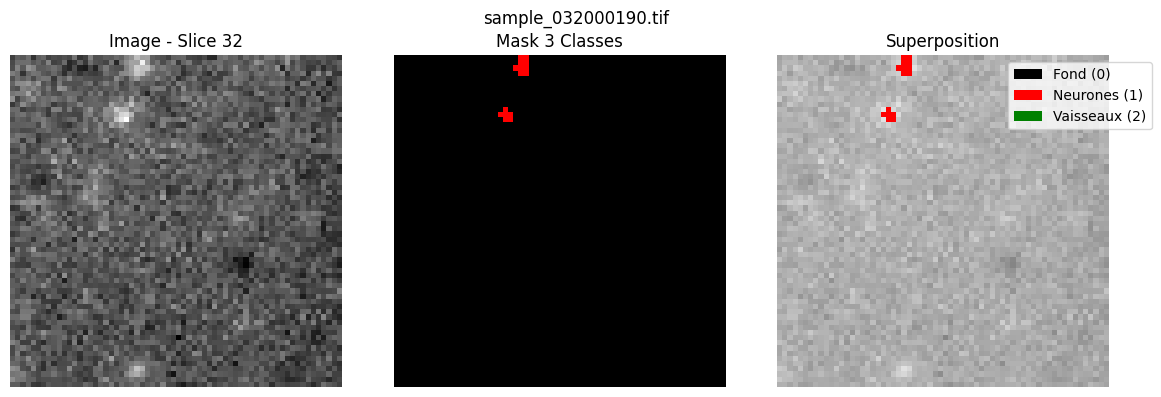

  Classe 0: 261,379
  Classe 1: 765
  Classe 2: 0

--- Patch 7/10: sample_083001219.tif ---


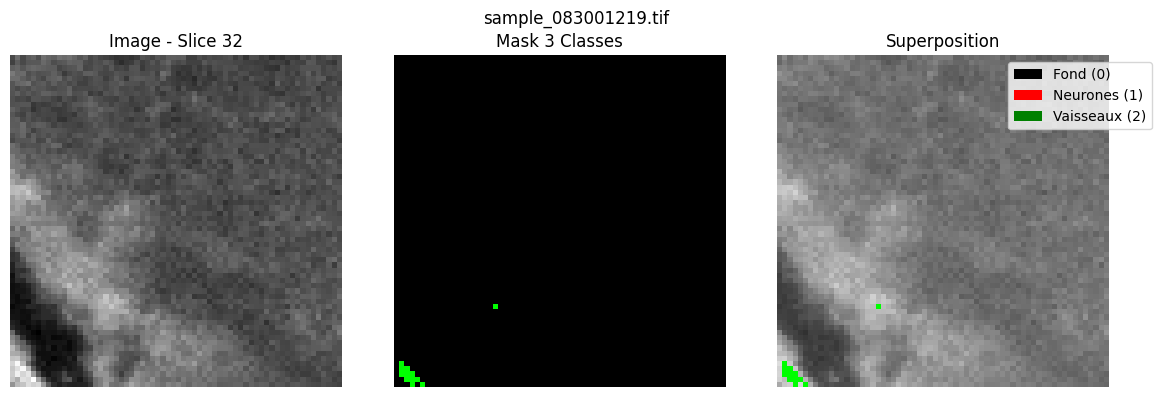

  Classe 0: 248,047
  Classe 1: 2
  Classe 2: 14,095

--- Patch 8/10: sample_012000025.tif ---


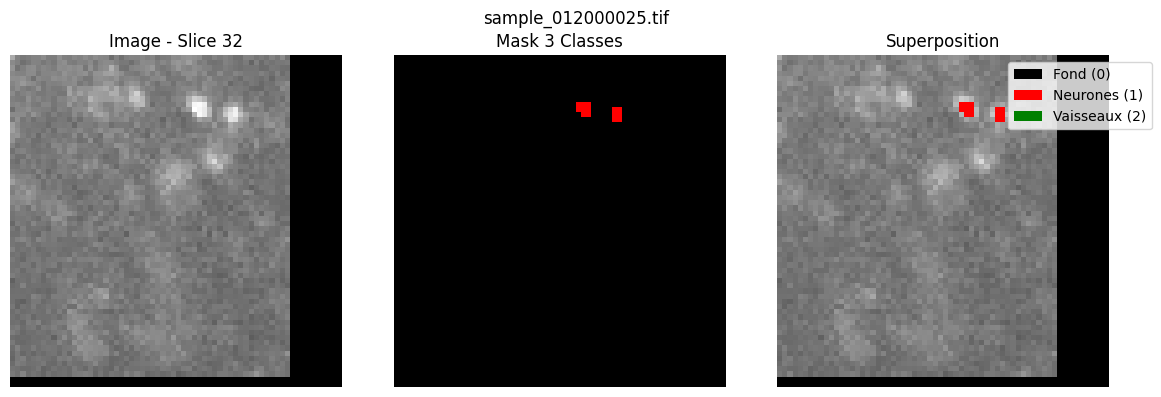

  Classe 0: 261,071
  Classe 1: 1,073
  Classe 2: 0

--- Patch 9/10: sample_032000254.tif ---


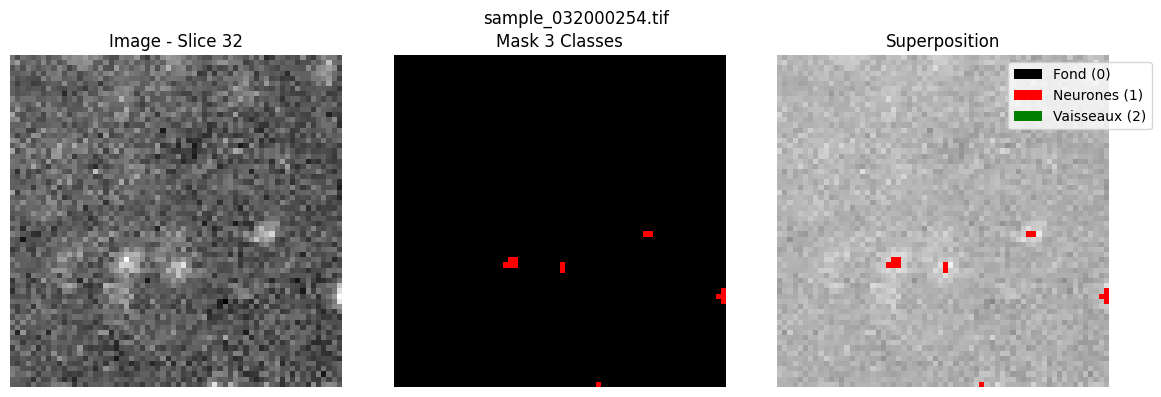

  Classe 0: 260,907
  Classe 1: 1,237
  Classe 2: 0

--- Patch 10/10: sample_056000051.tif ---


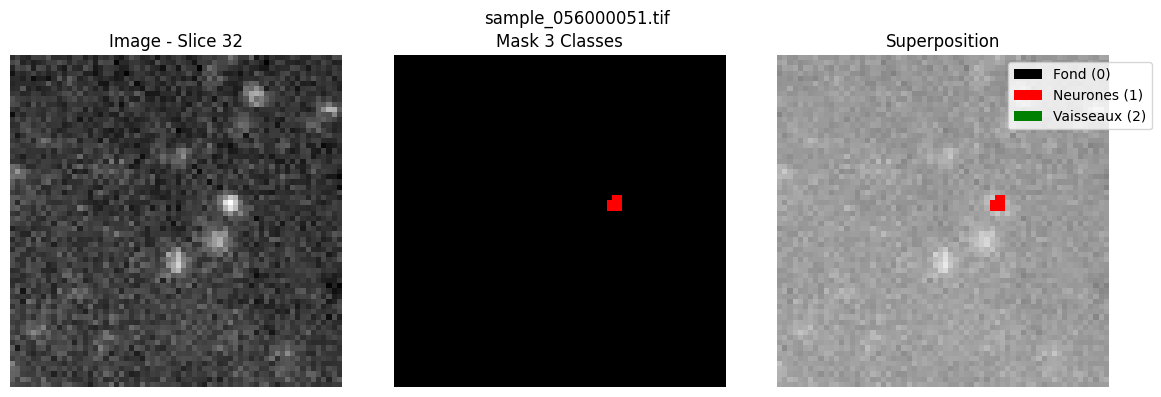

  Classe 0: 259,764
  Classe 1: 2,380
  Classe 2: 0

--- Patch 11/10: sample_032000470.tif ---


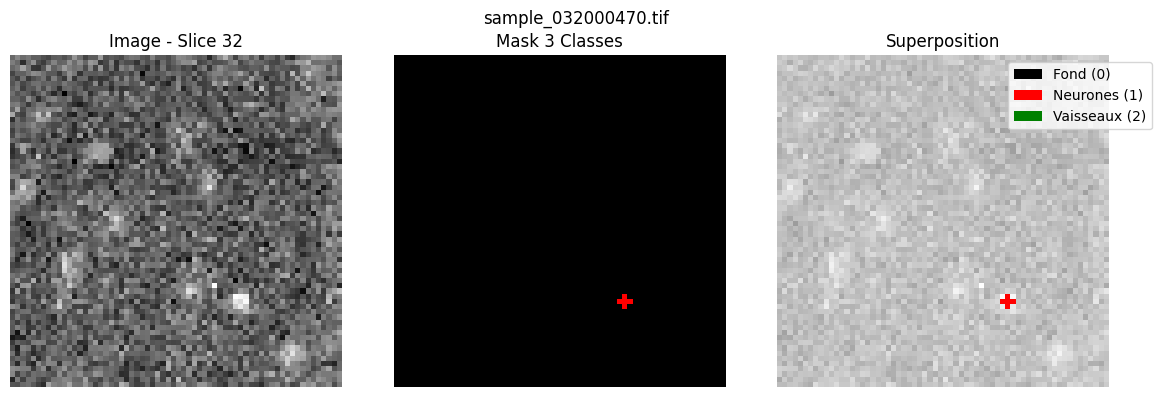

  Classe 0: 261,450
  Classe 1: 694
  Classe 2: 0

--- Patch 12/10: sample_035000121.tif ---


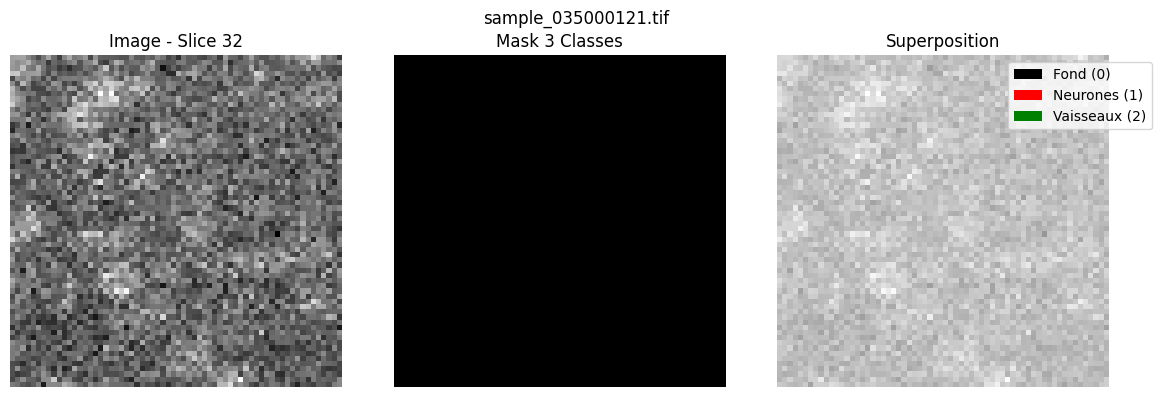

  Classe 0: 261,381
  Classe 1: 763
  Classe 2: 0

--- Patch 13/10: sample_073000073.tif ---


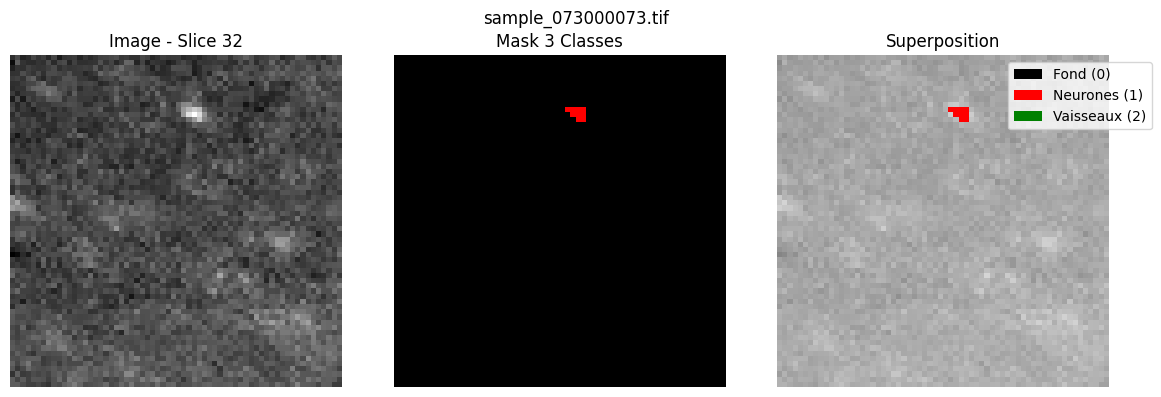

  Classe 0: 261,815
  Classe 1: 329
  Classe 2: 0

--- Patch 14/10: sample_012000041.tif ---


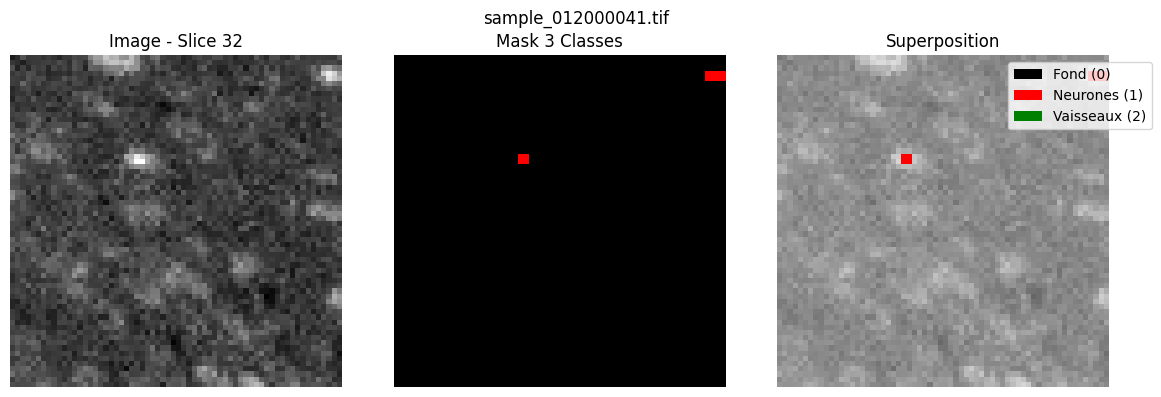

  Classe 0: 261,849
  Classe 1: 295
  Classe 2: 0

--- Patch 15/10: sample_049000063.tif ---


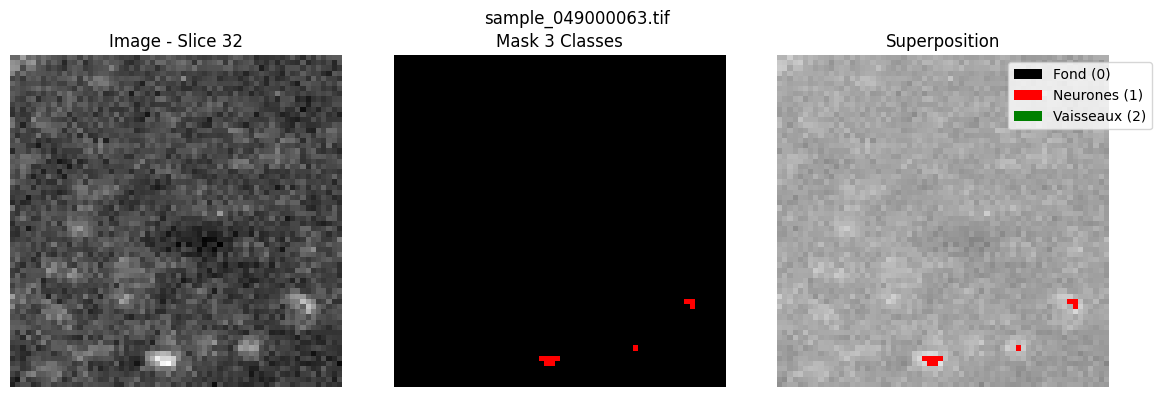

  Classe 0: 261,960
  Classe 1: 184
  Classe 2: 0

--- Patch 16/10: sample_049000040.tif ---


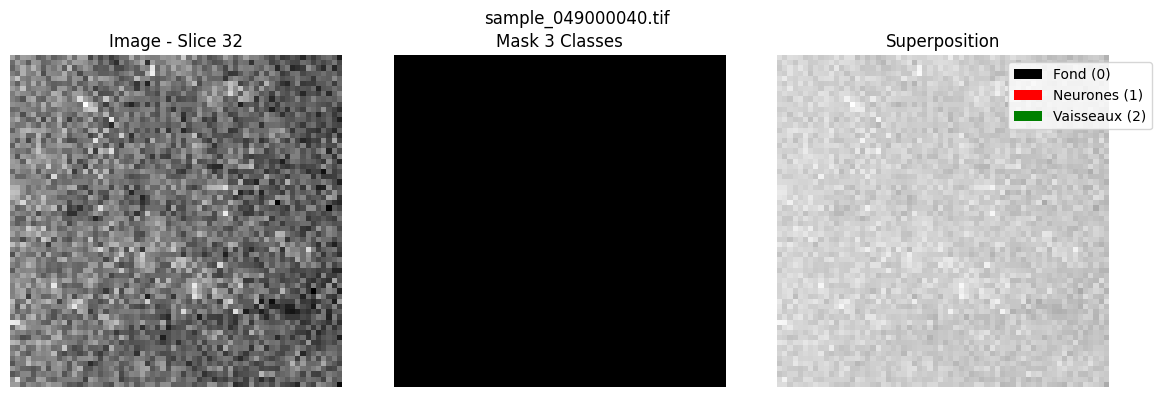

  Classe 0: 261,811
  Classe 1: 333
  Classe 2: 0

--- Patch 17/10: sample_052000022.tif ---


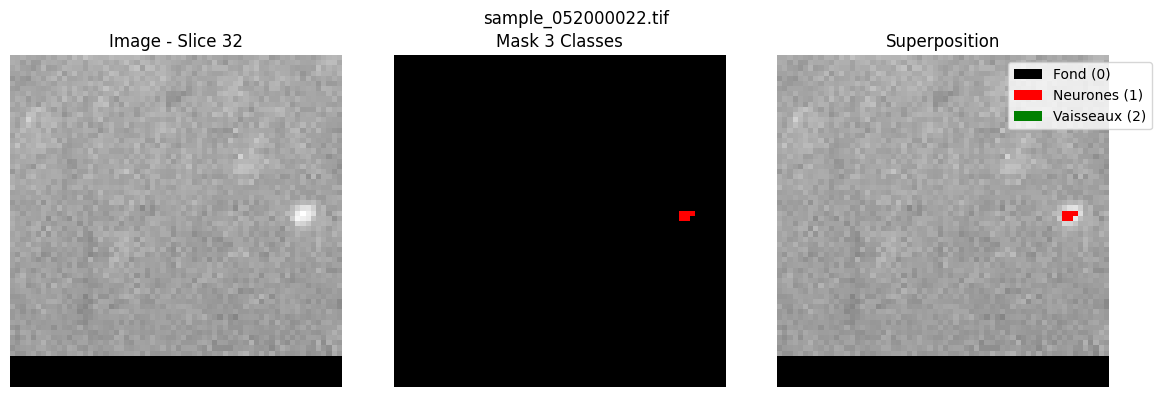

  Classe 0: 261,658
  Classe 1: 486
  Classe 2: 0

--- Patch 18/10: sample_077001932.tif ---


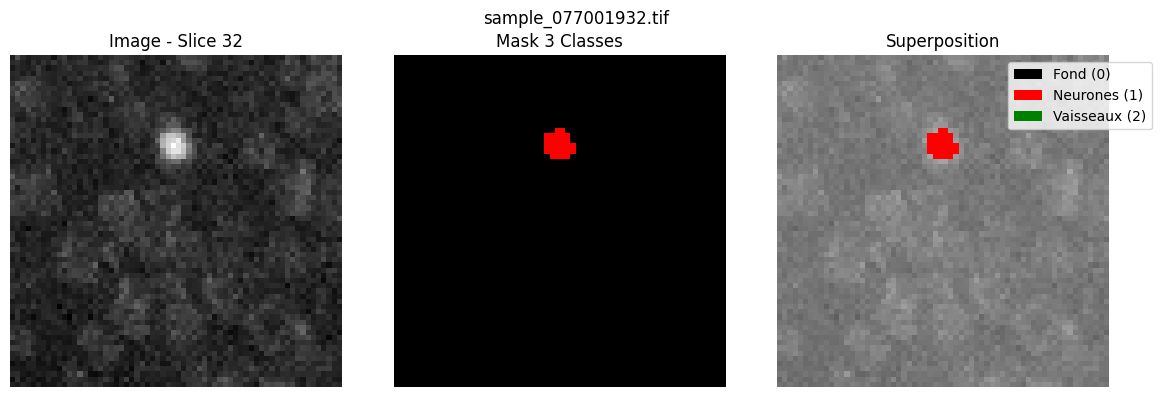

  Classe 0: 261,502
  Classe 1: 641
  Classe 2: 1

--- Patch 19/10: sample_037000202.tif ---


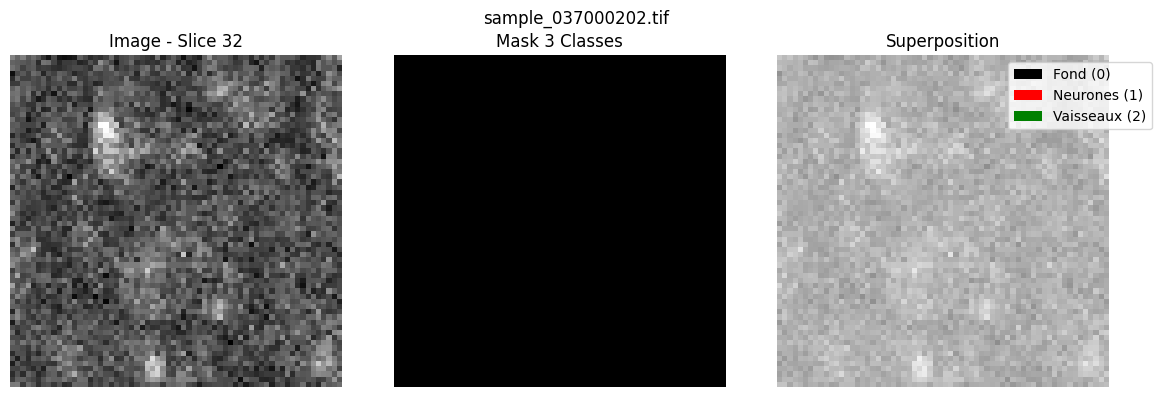

  Classe 0: 261,868
  Classe 1: 276
  Classe 2: 0

--- Patch 20/10: sample_005000009.tif ---


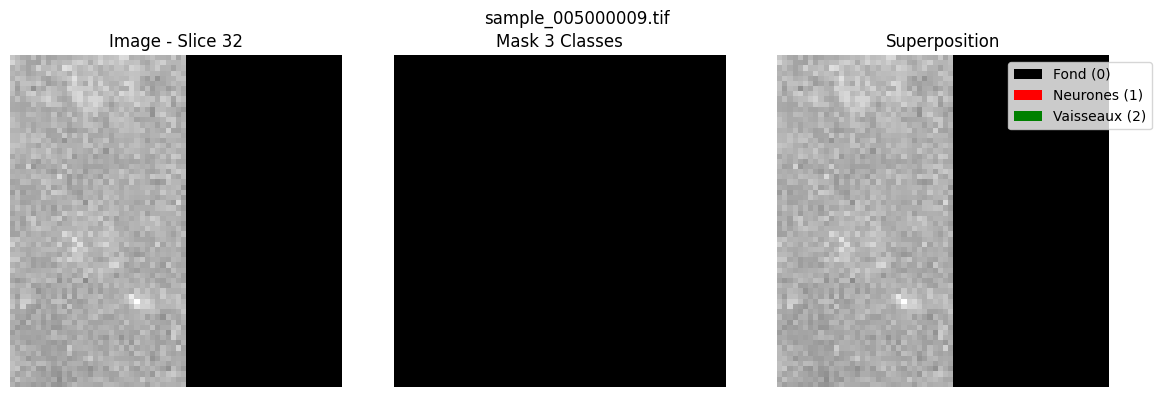

  Classe 0: 261,838
  Classe 1: 306
  Classe 2: 0


In [18]:

print("\n" + "=" * 50)
print("VISUALISATION DE 10 PATCHES ALÉATOIRES")
print("=" * 50)

# Sélectionner 10 indices aléatoires
random_indices = random.sample(selected_indices, min(20, len(selected_indices)))

for i, idx in enumerate(random_indices):
    print(f"\n--- Patch {i+1}/10: {image_files[idx].name} ---")
    show_patch(image_files[idx], mask_files[idx])